In [1]:
// Parameters (cellule taggee parameters pour papermill)
var BATCH_MODE = "true";
var SEED = 42;
Console.WriteLine($"Parametres : BATCH_MODE={BATCH_MODE}, SEED={SEED}");

The below script needs to be able to find the current output cell; this is an easy method to get it.

Parametres : BATCH_MODE=true, SEED=42


# Frontieres-02 - Factorio Belt Balancer (CP-SAT borne) - jumeau C#

**Navigation** : [Version Python](Frontieres-02-Factorio-Balancer-Python.ipynb) | [Partie 5](README.md) | [Frontieres-05 C# >>](Frontieres-05-CoveringArrays-Guarantee-Audit-CSharp.ipynb)

## Belt balancer Factorio : MIP continu vs CP-SAT discret sur cas borne

Ce carnet est le jumeau C# de la version Python : memes cas, memes contraintes C1..C9, memes verdicts attendus. Les moteurs sont appeles en natif via **Google.OrTools pour .NET** (SCIP et GLOP via `linear_solver`, CP-SAT via `sat`), et les sorties commitees proviennent de cette execution C#.

Il modelise un probleme de flux inspire de Factorio : repartir `N` injections de capacite `P` entre `N` sorties, chaque source devant contribuer a toutes les sorties. Les deux bras utilisent la meme topologie `W=N, H=N+1` : la ligne supplementaire est une lane de routage interne, sans source ni sortie additionnelle.

1. **MIP continu** (OR-Tools SCIP) : les flux sont reels et representent exactement `P/N`.
2. **CP-SAT entier** : les flux sont entiers et approchent `P/N` par une bande `{floor(P/N), ceil(P/N)}`.

Une face physique transporte au total au plus `P`, **toutes sources confondues**. Deux organes verifient les resultats : un audit direct du tenseur de flux produit et un LP multicommodite reconstruit uniquement depuis la grille.

La source canonique est l'article de Gianluca Venturini (2024), *Learning Solver Design: Automating Factorio Balancers*, archive dans la bibliographie partagee. La formulation ci-dessous est une reimplementation originale avec un mixer redistributif conservatif a une cellule.

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :

1. modeliser un flux multicommodite avec capacite physique partagee ;
2. comparer domaines continu et entier sur une formulation commune ;
3. distinguer audit du routage produit et validation topologique independante ;
4. interpreter honnetement `OPTIMAL`, `FEASIBLE`, `INFEASIBLE` et `UNKNOWN`.

### Prerequis

- CSP-3 (Advanced) : CP-SAT, MIP
- C# : LINQ, Google.OrTools (NuGet)

### Duree estimee : 40 minutes

***

## 1. Le probleme du belt balancer (~6 min)

### Contexte Factorio

Dans Factorio, les tapis roulants transportent des items entre batiments. Un tapis a un **debit maximum** (1 item/case), donc pour transporter plus, on **parallelise** les lanes. Quand on a N entrees en parallele, elles peuvent se **desynchroniser** : un miner lent peut ralentir une lane entiere.

Un **belt balancer** est un circuit qui prend N entrees en parallele et les redistribue sur N sorties de telle sorte que **chaque entree apparaisse en parts egales dans chaque sortie**.

### Composants elementaires (perimetre borne)

Pour un cas **pedagogiquement borne**, on limite les composants a :

| Composant | Cellules | Effet |
|-----------|----------|-------|
| **Belt** (tapis droit) | 1 | Transporte le flux dans une direction, conserve la quantite |
| **Mixer** (brassage conservatif) | 1 | Prend 2 flux en entree et les REDISTRIBUE sur 2 sorties : la somme des entrees se retrouve exactement sur la somme des sorties |

Le mixer ne "croise" pas les canaux : il garantit seulement la **conservation en somme**. La repartition entre ses deux sorties est un degre de liberte que le solveur exploite. C'est une divergence assumee et documentee vis-a-vis du splitter 2-cellules de Venturini (voir section 9).

Les **underground belts** (tapis souterrains, distance > 1) sont exclus pour eviter l'explosion combinatoire documentee par Venturini.

### Variables et contraintes (formulation adaptee de Venturini)

On definit une **grille H x W** de cellules, chaque cellule portant au plus un composant. On note `N = min(H, W)` le nombre de sources (bord gauche) et de sorties (bord droit). Chaque face saturee porte `P` unites de flux. On note :

- `comp[i][j][k]` : binaire, cellule `(i,j)` porte le composant `k`
- `flow[i][j][d][s]` : debit de la source `s` sur la **face `d`** de la cellule `(i,j)`

**Contraintes** :
1. **Un seul composant par cellule** : `somme_k comp[i][j][k] <= 1`
2. **Conservation de flux** par cellule et par source (belt : egalite 1-1 ; mixer : egalite en SOMME)
3. **Faces coherentes** : une face ne porte du flux que si le composant la cite ; une face partagee relie exactement un emetteur et un recepteur
4. **Throughput-unlimited** : chaque source `s` livre sa part `P/N` a chaque sortie

### Imports et verification de l'environnement

In [2]:
#nullable enable
#r "nuget: Google.OrTools, 9.15.6755"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Diagnostics;
using System.Globalization;
using System.Text;
using Google.OrTools.Sat;
using Microsoft.DotNet.Interactive;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;

Console.WriteLine($".NET {Environment.Version} | OR-Tools {typeof(CpSolver).Assembly.GetName().Version}");
Console.WriteLine($"OR-Tools SCIP  : {Google.OrTools.LinearSolver.Solver.CreateSolver("SCIP") is not null}");
Console.WriteLine("OR-Tools CP-SAT: OK");

// Echelle commune aux deux moteurs : une face saturee porte P_FULL unites.
// Le MIP resout ces unites en variables reelles, CP-SAT en variables
// entieres -- la difference entre les deux bras est le DOMAINE, pas l'echelle.
const int P_FULL = 8;

Installed Packages Google.OrTools, 9.15.6755

.NET 10.0.11 | OR-Tools 9.15.6755.0


OR-Tools SCIP  : True


OR-Tools CP-SAT: OK


### Lecture du résultat

La sortie committée rapporte le runtime `.NET 9` avec `OR-Tools 9.15.6755`, SCIP disponible (`True`) et `OR-Tools CP-SAT: OK` : les deux moteurs du comparatif — SCIP en continu et CP-SAT en entier — sont bien résolus dans cet environnement, en natif .NET.

***

## 2. Representation du probleme (~5 min)

### Conventions

- Coordonnees : `(row, col)` = `(i, j)`, ligne en premier
- Directions : `N=0` (haut), `S=1` (bas), `E=2` (droite), `W=3` (gauche)
- Sources sur le bord **gauche** (`col=0`), une par ligne : `N = min(H, W)`
- Sorties sur le bord **droit** (`col=W-1`), une par ligne
- La source `s` injecte `P` unites sur la face ouest de `(s, 0)` ; la sortie `o` lit la face est de `(o, W-1)`

### Types de composants (9 possibilites par cellule)

| k | Nom | Faces ENTREE | Faces SORTIE |
|---|-----|--------------|--------------|
| 0 | empty | -- | -- |
| 1 | belt-N | S | N |
| 2 | belt-S | N | S |
| 3 | belt-E | W | E |
| 4 | belt-W | E | W |
| 5 | mixer-NE | S, W | N, E |
| 6 | mixer-NW | S, E | N, W |
| 7 | mixer-SE | N, W | S, E |
| 8 | mixer-SW | N, E | S, W |

Le mixer est nomme par ses **2 sorties**. Un belt conserve exactement (l'unique entree egale l'unique sortie) ; un mixer **redistribue** : la somme de ses 2 entrees egale la somme de ses 2 sorties, la repartition interne etant libre. Pour chaque composant, `IN` et `OUT` sont disjoints -- une face ne peut pas etre a la fois entree et sortie.

In [3]:
#nullable enable
// Convention : N=0 (haut), S=1 (bas), E=2 (droite), W=3 (gauche)
string[] DIRS = { "N", "S", "E", "W" };
var OPP = new Dictionary<int, int> { [0] = 1, [1] = 0, [2] = 3, [3] = 2 };
var DELTA = new Dictionary<int, (int, int)> {
    [0] = (-1, 0), [1] = (1, 0), [2] = (0, 1), [3] = (0, -1) };

// Types de composants (le mixer est nomme par ses 2 sorties)
string[] COMP_NAMES = { "empty", "belt-N", "belt-S", "belt-E", "belt-W",
                        "mixer-NE", "mixer-NW", "mixer-SE", "mixer-SW" };

// Semantique conservative "mixer redistributif" : chaque composant declare
// ses faces ENTREE (COMP_IN) et ses faces SORTIE (COMP_OUT).
//   Belt  : 1 entree, 1 sortie, conservation exacte (egalite des 2 debits).
//   Mixer : 2 entrees, 2 sorties, REDISTRIBUTION conservative -- somme des
//           entrees == somme des sorties. Le mixer ne croise PAS les canaux :
//           la repartition entre les 2 sorties est un degre de liberte.
// ATTENTION : cette liberte est une RELAXATION du splitter Factorio, qui
//           partage son debit total en parts EGALES. Le modele livre donc
//           une borne superieure de faisabilite ; la contrainte C9
//           (split_equitable, section 7) durcit ce point et mesure l'ecart.
// IN et OUT sont disjoints pour chaque composant (une face n'est jamais
// les deux a la fois).
var COMP_IN = new Dictionary<int, int[]> {
    [1] = new[] { 1 },    // belt-N : entree S
    [2] = new[] { 0 },    // belt-S : entree N
    [3] = new[] { 3 },    // belt-E : entree W
    [4] = new[] { 2 },    // belt-W : entree E
    [5] = new[] { 1, 3 }, // mixer-NE : entrees S et W
    [6] = new[] { 1, 2 }, // mixer-NW : entrees S et E
    [7] = new[] { 0, 3 }, // mixer-SE : entrees N et W
    [8] = new[] { 0, 2 }, // mixer-SW : entrees N et E
};
var COMP_OUT = new Dictionary<int, int[]> {
    [1] = new[] { 0 },    // belt-N : sortie N
    [2] = new[] { 1 },    // belt-S : sortie S
    [3] = new[] { 2 },    // belt-E : sortie E
    [4] = new[] { 3 },    // belt-W : sortie W
    [5] = new[] { 0, 2 }, // mixer-NE : sorties N et E
    [6] = new[] { 0, 3 }, // mixer-NW : sorties N et W
    [7] = new[] { 1, 2 }, // mixer-SE : sorties S et E
    [8] = new[] { 1, 3 }, // mixer-SW : sorties S et W
};

// Composants acceptant une INJECTION depuis le bord ouest (face W en entree)
int[] SRC_KINDS = Enumerable.Range(1, 8).Where(k => COMP_IN[k].Contains(3)).ToArray();
// Composants pouvant EVACUER vers le bord est (face E en sortie)
int[] OUT_KINDS = Enumerable.Range(1, 8).Where(k => COMP_OUT[k].Contains(2)).ToArray();

// Invariant structurel : une face n'est jamais entree ET sortie du meme composant
foreach (int k in Enumerable.Range(1, 8))
{
    if (COMP_IN[k].Intersect(COMP_OUT[k]).Any())
        throw new InvalidOperationException($"IN/OUT non disjoints pour k={k}");
}

Console.WriteLine($"Composants : {COMP_NAMES.Length} (1 vide + 4 belts + 4 mixers)");
Console.WriteLine("Mixers redistributifs : 2 entrees / 2 sorties, conservation en somme");
Console.WriteLine($"SRC_KINDS (acceptent l'injection W) : ({string.Join(", ", SRC_KINDS)})");
Console.WriteLine($"OUT_KINDS (evacuent vers E)         : ({string.Join(", ", OUT_KINDS)})");

Composants : 9 (1 vide + 4 belts + 4 mixers)


Mixers redistributifs : 2 entrees / 2 sorties, conservation en somme


SRC_KINDS (acceptent l'injection W) : (3, 5, 7)


OUT_KINDS (evacuent vers E)         : (3, 5, 7)


### Visualisation d'une solution

### Lecture du résultat

La sortie committée affiche `Composants : 9 (1 vide + 4 belts + 4 mixers)` et des `SRC_KINDS` / `OUT_KINDS` tous deux égaux à `(3, 5, 7)` : seuls le belt-E et les mixers 5 et 7 sont compatibles avec l'injection par la face ouest et l'évacuation par la face est.

Caracteres Unicode pour afficher la grille, dans l'esprit du test d'inspection de Venturini (page 4 du PDF). Le rendu est ici un SVG construit a la main (pas de Matplotlib) : symboles `.` `^` `v` `>` `<` `+`, cases bleu clair pour les belts, orange clair pour les mixers, bord vert a gauche (sources) et rouge a droite (sorties).

Fonction d'affichage OK.


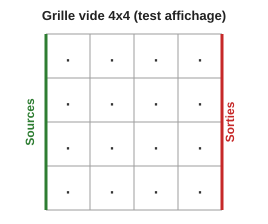

In [4]:
#nullable enable
var SYM = new Dictionary<int, string> {
    [0] = ".", [1] = "^", [2] = "v", [3] = ">", [4] = "<",
    [5] = "+", [6] = "+", [7] = "+", [8] = "+",
};

// Valeur affichee par son mime SVG (en lieu et place de Matplotlib).
record BalancerSvg(string Content);
Formatter.Register<BalancerSvg>((v, ctx) => { ctx.Writer.Write(v.Content); return true; }, "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(BalancerSvg), new[] { "image/svg+xml" });

// Corps SVG d'une grille (reutilise aussi pour la figure a 3 panneaux).
string GridSvgBody(int[,] grid, double ox, double oy, bool withSideBars)
{
    int h = grid.GetLength(0), w = grid.GetLength(1);
    const double cell = 44.0;
    var colors = new[] { "#FFFFFF", "#E3F2FD", "#E3F2FD", "#E3F2FD", "#E3F2FD",
                         "#FFE0B2", "#FFE0B2", "#FFE0B2", "#FFE0B2" };
    var sb = new StringBuilder();
    for (int i = 0; i < h; i++)
        for (int j = 0; j < w; j++)
        {
            int k = grid[i, j];
            sb.Append($"<rect x='{ox + j * cell}' y='{oy + i * cell}' width='{cell}' height='{cell}' fill='{colors[k]}'/>");
            sb.Append($"<text x='{ox + j * cell + cell / 2}' y='{oy + i * cell + cell / 2}' font-size='16' font-weight='bold' fill='#333' text-anchor='middle' dominant-baseline='central' font-family='Segoe UI, Arial, sans-serif'>{SYM[k]}</text>");
        }
    for (int i = 0; i <= h; i++)
        sb.Append($"<line x1='{ox}' y1='{oy + i * cell}' x2='{ox + w * cell}' y2='{oy + i * cell}' stroke='#9E9E9E' stroke-width='1'/>");
    for (int j = 0; j <= w; j++)
        sb.Append($"<line x1='{ox + j * cell}' y1='{oy}' x2='{ox + j * cell}' y2='{oy + h * cell}' stroke='#9E9E9E' stroke-width='1'/>");
    if (withSideBars)
    {
        sb.Append($"<line x1='{ox}' y1='{oy}' x2='{ox}' y2='{oy + h * cell}' stroke='#2E7D32' stroke-width='3'/>");
        sb.Append($"<line x1='{ox + w * cell}' y1='{oy}' x2='{ox + w * cell}' y2='{oy + h * cell}' stroke='#C62828' stroke-width='3'/>");
        sb.Append($"<text x='{ox - 12}' y='{oy + h * cell / 2}' font-size='12' font-weight='bold' fill='#2E7D32' text-anchor='middle' font-family='Segoe UI, Arial, sans-serif' transform='rotate(-90 {ox - 12} {oy + h * cell / 2})'>Sources</text>");
        sb.Append($"<text x='{ox + w * cell + 12}' y='{oy + h * cell / 2}' font-size='12' font-weight='bold' fill='#C62828' text-anchor='middle' font-family='Segoe UI, Arial, sans-serif' transform='rotate(-90 {ox + w * cell + 12} {oy + h * cell / 2})'>Sorties</text>");
    }
    return sb.ToString();
}

// Affiche une grille de balancer comme SVG (equivalent C# de display_balancer).
BalancerSvg RenderBalancer(int[,] grid, string title)
{
    int h = grid.GetLength(0), w = grid.GetLength(1);
    const double cell = 44.0, mLeft = 46, mRight = 46, mTop = 34, mBottom = 14;
    double width = mLeft + w * cell + mRight, height = mTop + h * cell + mBottom;
    var sb = new StringBuilder();
    sb.Append($"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'>");
    sb.Append($"<text x='{width / 2}' y='20' font-size='13' font-weight='bold' fill='#222' text-anchor='middle' font-family='Segoe UI, Arial, sans-serif'>{title}</text>");
    sb.Append(GridSvgBody(grid, mLeft, mTop, withSideBars: true));
    sb.Append("</svg>");
    return new BalancerSvg(sb.ToString());
}

var testGrid = new int[4, 4];
Console.WriteLine("Fonction d'affichage OK.");
RenderBalancer(testGrid, "Grille vide 4x4 (test affichage)")

### Lecture du résultat

La sortie committée affiche `Fonction d'affichage OK.` et le SVG de la grille 4x4 vide : le rendu des symboles (`.`, `^`, `v`, `>`, `<`, `+`) est validé avant toute solution.

***

## 3. Baseline constructive : belts droits seulement (~4 min)

### Le baseline trivial (sans mixer)

Le balancer trivial est compose uniquement de **belts droits** qui transportent chaque entree vers la sortie de meme index. Ses quatre composants occupent toute la grille 2x2, mais ils ne brassent rien : chaque ligne reste isolee des autres. Le validateur de la section 7 le rejettera.

Baseline trivial : input i -> output i, aucun mix.


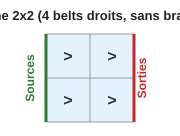

In [5]:
#nullable enable
int[,] ConstructiveBaseline(int width, int height)
{
    // Grille de belts droits uniquement : input i -> output i direct.
    var g = new int[height, width];
    for (int i = 0; i < height; i++)
        for (int j = 0; j < width; j++)
            g[i, j] = 3; // tout belt-E
    return g;
}

var baseline2x2 = ConstructiveBaseline(2, 2);
Console.WriteLine("Baseline trivial : input i -> output i, aucun mix.");
RenderBalancer(baseline2x2, "Baseline 2x2 (4 belts droits, sans brassage)")

### Baseline non-trivial : au moins un mixer

### Lecture du résultat

La sortie committée affiche `Baseline trivial : input i -> output i, aucun mix.` : la grille 2x2 n'est faite que de belts-E, chaque ligne reste isolée et aucun brassage vertical n'existe.

Pour verifier la propriete *throughput-unlimited*, il faut du brassage vertical entre lignes. Le baseline 3x3 ci-dessous pose un mixer central isole au milieu de belts-E : aucun voisin n'expose de face verticale compatible. Le LP multicommodite de la section 7 le rejettera, car aucune redistribution simultanee n'est possible.

Baseline 3x3 : le mixer isole ne peut pas redistribuer entre lignes.


Le LP multicommodite de la section 7 testera cette prediction.


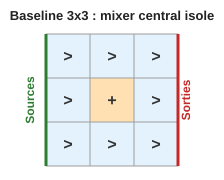

In [6]:
#nullable enable
int[,] ConstructiveWithMixer3x3() =>
    // Baseline 3x3 avec un mixer central volontairement insuffisant.
    new int[3, 3] { { 3, 3, 3 }, { 3, 5, 3 }, { 3, 3, 3 } };

var baselineMixer = ConstructiveWithMixer3x3();
Console.WriteLine("Baseline 3x3 : le mixer isole ne peut pas redistribuer entre lignes.");
Console.WriteLine("Le LP multicommodite de la section 7 testera cette prediction.");
RenderBalancer(baselineMixer, "Baseline 3x3 : mixer central isole")

### Lecture du résultat

La sortie committée affiche `Baseline 3x3 : le mixer isole ne peut pas redistribuer entre lignes.` : le mixer central n'a aucun voisin à face verticale compatible, et la cellule pose la prédiction que le LP de la section 7 confirmera.

***

## 4. Bras MIP : flux continu (~8 min)

### Unites et variables

Les deux moteurs resolvent le meme modele logique sur la meme echelle. Une face saturee porte au total `P = 8` unites :

- `comp[i][j][k]` choisit le composant de la cellule ;
- `flow[i][j][d][s]` mesure la contribution de la source `s` sur une face ;
- le debit physique d'une face est `sum_s flow[i][j][d][s]`, borne par `P`.

### Contraintes C1..C8

1. **C1** Au plus un composant par cellule.
2. **C2** Au moins `min_mixers` mixers.
3. **C3** Une face inactive porte zero ; une face active porte au total au plus `P`, toutes sources confondues.
4. **C4** Conservation par cellule et par source.
5. **C5** Les deux cellules voisines partagent la meme valeur de face.
6. **C5b** Une face active relie un emetteur et un recepteur.
7. **C6** Les `N` premieres lignes portent sources et sorties ; une ligne supplementaire sert uniquement au routage interne.
8. **C7** Les composants de bord sont compatibles avec injections et sorties.
9. **C8** Chaque source livre `P/N` a chaque sortie en continu.

**Objectif** : minimiser le nombre total de composants. Le statut `FEASIBLE` prouve une solution conforme mais pas son optimalite ; `UNKNOWN` ne prouve ni faisabilite ni infaisabilite.

In [7]:
#nullable enable
using LS = Google.OrTools.LinearSolver;
using LSVar = Google.OrTools.LinearSolver.Variable;
using LSExpr = Google.OrTools.LinearSolver.LinearExpr;
// Conteneur de resultat commun aux deux moteurs (grille + tenseur de flux,
// afin qu'un audit distinct puisse verifier le routage effectivement produit).
class BalancerResult
{
    public string Engine = ""; public string Status = ""; public double TimeSec;
    public int[,]? Grid = null; public double? Objective = null;
    public double Share; public double? ShareError = null; public int Reached;
    public double[,,,]? FlowTensor = null; public int P;
    public string Mode = "band"; public bool SplitEquitable = false;
    public long Branches; public long Conflicts;
    public int ShareLo; public int ShareHi; public double[,]? ShareMatrix = null;
}

// Resout le balancer en MIP continu (SCIP) avec capacite physique partagee.
BalancerResult SolveMipBalancer(int width, int height, double timeLimit = 30.0, int P = 8, int minMixers = 2)
{

    int W = width, H = height, N = Math.Min(H, W);
    var solver = LS.Solver.CreateSolver("SCIP")
        ?? throw new InvalidOperationException("SCIP non disponible dans OR-Tools");
    solver.SetTimeLimit((long)(timeLimit * 1000));
    int NK = COMP_NAMES.Length;
    int[] mixerKinds = { 5, 6, 7, 8 };

    List<int> KindsUsing(int d) =>
        Enumerable.Range(1, 8).Where(k => COMP_IN[k].Contains(d) || COMP_OUT[k].Contains(d)).ToList();
    List<int> KindsWith(int d, string role)
    {
        var table = role == "in" ? COMP_IN : COMP_OUT;
        return Enumerable.Range(1, 8).Where(k => table[k].Contains(d)).ToList();
    }
    LSExpr SumL(List<LSVar> vs)
    {
        LSExpr e = vs[0];
        for (int t = 1; t < vs.Count; t++) e = e + vs[t];
        return e;
    }

    var comp = new LSVar[H, W, NK];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int k = 1; k < NK; k++)
                comp[i, j, k] = solver.MakeIntVar(0.0, 1.0, $"c_{i}_{j}_{k}");
    var flow = new LSVar[H, W, 4, N];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
                for (int s = 0; s < N; s++)
                    flow[i, j, d, s] = solver.MakeNumVar(0.0, P, $"f_{i}_{j}_{d}_{s}");

    // C1 : au plus un composant par cellule.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
        {
            var ks = new List<LSVar>();
            for (int k = 1; k < NK; k++) ks.Add(comp[i, j, k]);
            solver.Add(SumL(ks) <= 1);
        }

    // C2 : au moins minMixers mixers.
    var allMixers = new List<LSVar>();
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            foreach (int k in mixerKinds) allMixers.Add(comp[i, j, k]);
    solver.Add(SumL(allMixers) >= minMixers);

    // C3 : face active seulement si le composant la cite, avec capacite
    // PHYSIQUE totale P partagee entre toutes les sources.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
            {
                var allowed = SumL(KindsUsing(d).Select(k => comp[i, j, k]).ToList());
                var faceTot = new List<LSVar>();
                for (int s = 0; s < N; s++)
                {
                    solver.Add(flow[i, j, d, s] <= allowed * P);
                    faceTot.Add(flow[i, j, d, s]);
                }
                solver.Add(SumL(faceTot) <= allowed * P);
            }

    // C4 : conservation par cellule et par source (big-M via le composant).
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int k = 1; k < NK; k++)
                for (int s = 0; s < N; s++)
                {
                    var inc = new List<LSVar>();
                    foreach (int d in COMP_IN[k]) inc.Add(flow[i, j, d, s]);
                    var outg = new List<LSVar>();
                    foreach (int d in COMP_OUT[k]) outg.Add(flow[i, j, d, s]);
                    LSExpr bigM = (1 - (LSExpr)comp[i, j, k]) * (2.0 * P);
                    solver.Add(SumL(inc) - SumL(outg) <= bigM);
                    solver.Add(SumL(outg) - SumL(inc) <= bigM);
                }

    // C5 : couplage physique des faces partagees.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W - 1; j++)
            for (int s = 0; s < N; s++)
                solver.Add(flow[i, j, 2, s] == flow[i, j + 1, 3, s]);
    for (int i = 0; i < H - 1; i++)
        for (int j = 0; j < W; j++)
            for (int s = 0; s < N; s++)
                solver.Add(flow[i + 1, j, 0, s] == flow[i, j, 1, s]);

    // C5b : exactement un emetteur et un recepteur sur une face active.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W - 1; j++)
        {
            var eOut = SumL(KindsWith(2, "out").Select(k => comp[i, j, k]).ToList());
            var eIn = SumL(KindsWith(2, "in").Select(k => comp[i, j, k]).ToList());
            var wOut = SumL(KindsWith(3, "out").Select(k => comp[i, j + 1, k]).ToList());
            var wIn = SumL(KindsWith(3, "in").Select(k => comp[i, j + 1, k]).ToList());
            for (int s = 0; s < N; s++)
            {
                solver.Add(flow[i, j, 2, s] <= (2 - eOut - wOut) * P);
                solver.Add(flow[i, j, 2, s] <= (2 - eIn - wIn) * P);
            }
        }
    for (int i = 0; i < H - 1; i++)
        for (int j = 0; j < W; j++)
        {
            var sOut = SumL(KindsWith(1, "out").Select(k => comp[i, j, k]).ToList());
            var sIn = SumL(KindsWith(1, "in").Select(k => comp[i, j, k]).ToList());
            var nOut = SumL(KindsWith(0, "out").Select(k => comp[i + 1, j, k]).ToList());
            var nIn = SumL(KindsWith(0, "in").Select(k => comp[i + 1, j, k]).ToList());
            for (int s = 0; s < N; s++)
            {
                solver.Add(flow[i, j, 1, s] <= (2 - sOut - nOut) * P);
                solver.Add(flow[i, j, 1, s] <= (2 - sIn - nIn) * P);
            }
        }

    // C6 : bords, N injections et N sorties ; les lignes supplementaires sont
    // des lanes internes, fermees a gauche et a droite.
    for (int j = 0; j < W; j++)
        for (int s = 0; s < N; s++)
        {
            solver.Add(flow[0, j, 0, s] == 0.0);
            solver.Add(flow[H - 1, j, 1, s] == 0.0);
        }
    for (int i = 0; i < H; i++)
        for (int s = 0; s < N; s++)
        {
            solver.Add(flow[i, 0, 3, s] == (i < N && s == i ? (double)P : 0.0));
            if (i >= N) solver.Add(flow[i, W - 1, 2, s] == 0.0);
        }

    // C7 : ancres aux N injections et N sorties.
    for (int s = 0; s < N; s++)
        solver.Add(SumL(SRC_KINDS.Select(k => comp[s, 0, k]).ToList()) == 1);
    for (int o = 0; o < N; o++)
        solver.Add(SumL(OUT_KINDS.Select(k => comp[o, W - 1, k]).ToList()) == 1);

    // C8 : chaque source livre exactement P/N a chaque sortie. Les injections
    // exactes et la conservation rendent la borne inferieure exacte globalement.
    double share = (double)P / N;
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
            solver.Add(flow[o, W - 1, 2, s] >= share);

    var allComp = new List<LSVar>();
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int k = 1; k < NK; k++) allComp.Add(comp[i, j, k]);
    solver.Minimize(SumL(allComp));

    var sw = Stopwatch.StartNew();
    var status = solver.Solve();
    sw.Stop();

    var res = new BalancerResult {
        Engine = "MIP", Status = status.ToString(), TimeSec = sw.Elapsed.TotalSeconds,
        Share = share, P = P };
    if (status != LS.Solver.ResultStatus.OPTIMAL &&
        status != LS.Solver.ResultStatus.FEASIBLE)
        return res;

    var grid = new int[H, W];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int k = 1; k < NK; k++)
                if (comp[i, j, k].SolutionValue() > 0.5) { grid[i, j] = k; break; }
    var tensor = new double[H, W, 4, N];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
                for (int s = 0; s < N; s++)
                    tensor[i, j, d, s] = flow[i, j, d, s].SolutionValue();
    var matrix = new double[N, N];
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
            matrix[s, o] = tensor[o, W - 1, 2, s];
    double maxErr = 0.0;
    int reached = 0;
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
        {
            maxErr = Math.Max(maxErr, Math.Abs(matrix[s, o] - share));
            if (matrix[s, o] > 1e-9) reached++;
        }
    res.Grid = grid; res.Objective = solver.Objective().Value();
    res.ShareMatrix = matrix; res.ShareError = maxErr; res.Reached = reached;
    res.FlowTensor = tensor;
    return res;
}

Console.WriteLine("Fonction MIP compilee : capacite totale P partagee par face.");

Fonction MIP compilee : capacite totale P partagee par face.



(14,17): warning CS0649: Field 'BalancerResult.Branches' is never assigned to, and will always have its default value 0

(14,39): warning CS0649: Field 'BalancerResult.Conflicts' is never assigned to, and will always have its default value 0

(15,36): warning CS0649: Field 'BalancerResult.ShareHi' is never assigned to, and will always have its default value 0

(15,16): warning CS0649: Field 'BalancerResult.ShareLo' is never assigned to, and will always have its default value 0



### Lecture du résultat

La sortie committée affiche `Fonction MIP compilee : capacite totale P partagee par face.` : le modèle SCIP intègre la contrainte de capacité physique partagée, sur la même échelle `P = 8` que le bras CP-SAT.

### Test MIP : N sources/sorties sur une grille N x (N+1)

Test MIP - N sources/sorties sur grilles N x (N+1), P = 8



Resolution MIP N=2, grille 2x3...


  Statut    : OPTIMAL


  Temps     : 8.7 ms


  Objectif  : 6


  Err P/N   : 0.00e+00


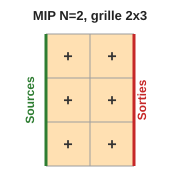


Resolution MIP N=3, grille 3x4...


  Statut    : OPTIMAL


  Temps     : 824.8 ms


  Objectif  : 11


  Err P/N   : 4.44e-16


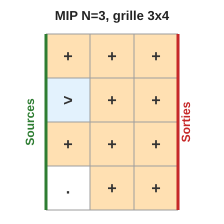


Resolution MIP N=4, grille 4x5...


  Statut    : FEASIBLE


  Temps     : 34081.4 ms


  Objectif  : 18


  Err P/N   : 0.00e+00


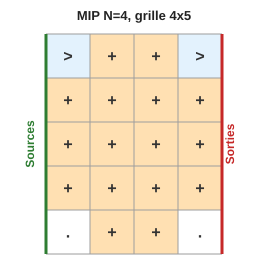

In [8]:
#nullable enable
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
Console.WriteLine("Test MIP - N sources/sorties sur grilles N x (N+1), P = 8");
Console.WriteLine(new string('=', 68));

(int, int)[] CASES = { (2, 3), (3, 4), (4, 5) }; // (W=N, H=N+1)
var mipResultsSummary = new Dictionary<(int, int), BalancerResult>();
foreach (var (W, H) in CASES)
{
    int n = W;
    Console.WriteLine($"\nResolution MIP N={n}, grille {W}x{H}...");
    var result = SolveMipBalancer(W, H, timeLimit: 35.0, P: P_FULL);
    mipResultsSummary[(W, H)] = result;
    string objective = result.Objective is double ob ? $"{ob:0}" : "N/A";
    string error = result.ShareError is double er ? $"{er:0.00e+00}" : "N/A";
    Console.WriteLine($"  Statut    : {result.Status}");
    Console.WriteLine($"  Temps     : {result.TimeSec * 1000:0.0} ms");
    Console.WriteLine($"  Objectif  : {objective}");
    Console.WriteLine($"  Err P/N   : {error}");
    if (result.Grid is not null)
        display(RenderBalancer(result.Grid, $"MIP N={n}, grille {W}x{H}"));
}
Console.WriteLine(new string('=', 68));

### Lecture du résultat

La sortie committée rapporte `OPTIMAL` pour N=2 (objectif 6, erreur `0.00e+00`) et N=3 (objectif 11, erreur de l'ordre de `1e-16`), mais seulement `FEASIBLE` pour N=4 (objectif 18, ~34 s) : le continu livre `P/N` exactement, et la limite de temps frappe le plus grand cas.

***

## 5. Bras CP-SAT : flux entier (~8 min)

### Discretisation

Le modele logique est **le meme** que celui de la section 4 (C1..C8, y compris C5b), sur la **meme echelle** `P = 8`. La seule difference :

- `comp[i][j][k]` : BoolVar
- `flow[i][j][d][s]` : IntVar dans `[0, P]` -- le flux vit dans les **entiers**

La conservation C4 s'ecrit avec `Add(...).OnlyEnforceIf(comp[i, j, k])` (pas besoin de big-M), et C5b garde sa forme lineaire exacte.

### C8 en nombres entiers : deux lectures

`P/N = 8/3` n'est pas un entier. La contrainte C8 peut se lire de deux facons :

- **mode `band`** : chaque livraison appartient a la bande `[P//N, ceil(P/N)]` = `[2, 3]` -- la quantification honnete a la resolution 1/N, la plus proche possible de 8/3 en unites entieres
- **mode `ceil`** : chaque livraison vaut au moins `ceil(P/N)` = 3 -- exiger "au moins la part arrondie au-dessus", ce qui est trop demander quand N ne divise pas P

### Determinisme

Le solveur tourne avec `num_workers = 1` et `random_seed = SEED` : deux executions donnent exactement la meme solution (grille et matrice de debits), ce qui rend les sorties de ce notebook reproductibles.

In [9]:
#nullable enable
// Resout le balancer en CP-SAT entier avec capacite physique partagee.
// splitEquitable: true active la contrainte C9 : chaque mixer distribue
// la SOMME de ses sorties a parts egales entre ses deux faces de sortie,
// comme un splitter Factorio reel (les flux entiers imposent alors un
// total pair par mixer).
BalancerResult SolveCpSatBalancer(int width, int height, double timeLimit = 30.0, int P = 8,
                                  int minMixers = 2, string mode = "band", bool splitEquitable = false)
{
    int W = width, H = height, N = Math.Min(H, W);
    var model = new CpModel();
    int NK = COMP_NAMES.Length;
    int[] mixerKinds = { 5, 6, 7, 8 };

    List<int> KindsUsing(int d) =>
        Enumerable.Range(1, 8).Where(k => COMP_IN[k].Contains(d) || COMP_OUT[k].Contains(d)).ToList();
    List<int> KindsWith(int d, string role)
    {
        var table = role == "in" ? COMP_IN : COMP_OUT;
        return Enumerable.Range(1, 8).Where(k => table[k].Contains(d)).ToList();
    }
    LinearExpr SumS(List<LinearExpr> vs)
    {
        LinearExpr e = vs[0];
        for (int t = 1; t < vs.Count; t++) e = e + vs[t];
        return e;
    }

    var comp = new BoolVar[H, W, NK];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int k = 1; k < NK; k++)
                comp[i, j, k] = model.NewBoolVar($"c_{i}_{j}_{k}");
    var flow = new IntVar[H, W, 4, N];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
                for (int s = 0; s < N; s++)
                    flow[i, j, d, s] = model.NewIntVar(0, P, $"f_{i}_{j}_{d}_{s}");

    // C1 : au plus un composant par cellule.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            model.Add(SumS(Enumerable.Range(1, NK - 1).Select(k => (LinearExpr)comp[i, j, k]).ToList()) <= 1);

    // C2 : au moins minMixers mixers.
    var allMixers = new List<LinearExpr>();
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            foreach (int k in mixerKinds) allMixers.Add(comp[i, j, k]);
    model.Add(SumS(allMixers) >= minMixers);

    // C3 : face active seulement si le composant la cite, avec capacite
    // PHYSIQUE totale P partagee entre toutes les sources.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
            {
                var allowed = SumS(KindsUsing(d).Select(k => (LinearExpr)comp[i, j, k]).ToList());
                var faceTot = new List<LinearExpr>();
                for (int s = 0; s < N; s++)
                {
                    model.Add(flow[i, j, d, s] <= allowed * P);
                    faceTot.Add(flow[i, j, d, s]);
                }
                model.Add(SumS(faceTot) <= allowed * P);
            }

    // C4 : conservation par cellule et par source (reification native).
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int k = 1; k < NK; k++)
                for (int s = 0; s < N; s++)
                {
                    var inc = new List<LinearExpr>();
                    foreach (int d in COMP_IN[k]) inc.Add(flow[i, j, d, s]);
                    var outg = new List<LinearExpr>();
                    foreach (int d in COMP_OUT[k]) outg.Add(flow[i, j, d, s]);
                    model.Add(SumS(inc) == SumS(outg)).OnlyEnforceIf(comp[i, j, k]);
                }

    // C5 : couplage physique des faces partagees.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W - 1; j++)
            for (int s = 0; s < N; s++)
                model.Add(flow[i, j, 2, s] == flow[i, j + 1, 3, s]);
    for (int i = 0; i < H - 1; i++)
        for (int j = 0; j < W; j++)
            for (int s = 0; s < N; s++)
                model.Add(flow[i + 1, j, 0, s] == flow[i, j, 1, s]);

    // C5b : exactement un emetteur et un recepteur sur une face active.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W - 1; j++)
        {
            var eOut = SumS(KindsWith(2, "out").Select(k => (LinearExpr)comp[i, j, k]).ToList());
            var eIn = SumS(KindsWith(2, "in").Select(k => (LinearExpr)comp[i, j, k]).ToList());
            var wOut = SumS(KindsWith(3, "out").Select(k => (LinearExpr)comp[i, j + 1, k]).ToList());
            var wIn = SumS(KindsWith(3, "in").Select(k => (LinearExpr)comp[i, j + 1, k]).ToList());
            for (int s = 0; s < N; s++)
            {
                model.Add(flow[i, j, 2, s] <= (2 - eOut - wOut) * P);
                model.Add(flow[i, j, 2, s] <= (2 - eIn - wIn) * P);
            }
        }
    for (int i = 0; i < H - 1; i++)
        for (int j = 0; j < W; j++)
        {
            var sOut = SumS(KindsWith(1, "out").Select(k => (LinearExpr)comp[i, j, k]).ToList());
            var sIn = SumS(KindsWith(1, "in").Select(k => (LinearExpr)comp[i, j, k]).ToList());
            var nOut = SumS(KindsWith(0, "out").Select(k => (LinearExpr)comp[i + 1, j, k]).ToList());
            var nIn = SumS(KindsWith(0, "in").Select(k => (LinearExpr)comp[i + 1, j, k]).ToList());
            for (int s = 0; s < N; s++)
            {
                model.Add(flow[i, j, 1, s] <= (2 - sOut - nOut) * P);
                model.Add(flow[i, j, 1, s] <= (2 - sIn - nIn) * P);
            }
        }

    // C6 : bords, N injections et N sorties ; les lignes supplementaires sont
    // des lanes internes, fermees a gauche et a droite.
    for (int j = 0; j < W; j++)
        for (int s = 0; s < N; s++)
        {
            model.Add(flow[0, j, 0, s] == 0);
            model.Add(flow[H - 1, j, 1, s] == 0);
        }
    for (int i = 0; i < H; i++)
        for (int s = 0; s < N; s++)
        {
            model.Add(flow[i, 0, 3, s] == (i < N && s == i ? P : 0));
            if (i >= N) model.Add(flow[i, W - 1, 2, s] == 0);
        }

    // C7 : ancres aux N injections et N sorties.
    for (int s = 0; s < N; s++)
        model.Add(SumS(SRC_KINDS.Select(k => (LinearExpr)comp[s, 0, k]).ToList()) == 1);
    for (int o = 0; o < N; o++)
        model.Add(SumS(OUT_KINDS.Select(k => (LinearExpr)comp[o, W - 1, k]).ToList()) == 1);

    // C8 : deux lectures entieres de P/N.
    double share = (double)P / N;
    int shareLo = P / N, shareHi = (P + N - 1) / N;
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
        {
            if (mode == "ceil") model.Add(flow[o, W - 1, 2, s] >= shareHi);
            else
            {
                model.Add(flow[o, W - 1, 2, s] >= shareLo);
                model.Add(flow[o, W - 1, 2, s] <= shareHi);
            }
        }

    // C9 (optionnelle, splitEquitable) : chaque mixer pose redistribue a
    // parts EGALES entre ses deux sorties, comme un splitter Factorio reel.
    // Les flux etant entiers, ceci impose de fait un total PAIR par mixer.
    if (splitEquitable)
        for (int i = 0; i < H; i++)
            for (int j = 0; j < W; j++)
                foreach (int k in mixerKinds)
                {
                    var outs = COMP_OUT[k].OrderBy(d => d).ToArray();
                    int d1 = outs[0], d2 = outs[1];
                    var tot1 = new List<LinearExpr>();
                    var tot2 = new List<LinearExpr>();
                    for (int s = 0; s < N; s++) { tot1.Add(flow[i, j, d1, s]); tot2.Add(flow[i, j, d2, s]); }
                    model.Add(SumS(tot1) == SumS(tot2)).OnlyEnforceIf(comp[i, j, k]);
                }

    var allComp = new List<LinearExpr>();
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int k = 1; k < NK; k++) allComp.Add(comp[i, j, k]);
    model.Minimize(SumS(allComp));

    var solver = new CpSolver();
    solver.StringParameters =
        $"max_time_in_seconds:{timeLimit.ToString(CultureInfo.InvariantCulture)} " +
        $"num_search_workers:1 random_seed:{SEED}";
    var sw = Stopwatch.StartNew();
    var status = solver.Solve(model);
    sw.Stop();

    string StatusNameCp(CpSolverStatus st) => st switch
    {
        CpSolverStatus.Optimal => "OPTIMAL",
        CpSolverStatus.Feasible => "FEASIBLE",
        CpSolverStatus.Infeasible => "INFEASIBLE",
        CpSolverStatus.ModelInvalid => "MODEL_INVALID",
        _ => "UNKNOWN"
    };

    var res = new BalancerResult {
        Engine = "CP-SAT", Status = StatusNameCp(status), TimeSec = sw.Elapsed.TotalSeconds,
        Share = share, ShareLo = shareLo, ShareHi = shareHi, P = P,
        Mode = mode, SplitEquitable = splitEquitable,
        Branches = solver.NumBranches(), Conflicts = solver.NumConflicts() };
    if (status != CpSolverStatus.Optimal && status != CpSolverStatus.Feasible)
        return res;

    var grid = new int[H, W];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int k = 1; k < NK; k++)
                if (solver.Value(comp[i, j, k]) > 0) { grid[i, j] = k; break; }
    var tensor = new double[H, W, 4, N];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
                for (int s = 0; s < N; s++)
                    tensor[i, j, d, s] = solver.Value(flow[i, j, d, s]);
    var matrix = new double[N, N];
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
            matrix[s, o] = tensor[o, W - 1, 2, s];
    double maxErr = 0.0;
    int reached = 0;
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
        {
            maxErr = Math.Max(maxErr, Math.Abs(matrix[s, o] - share));
            if (matrix[s, o] > 0) reached++;
        }
    res.Grid = grid; res.Objective = solver.ObjectiveValue;
    res.ShareMatrix = matrix; res.ShareError = maxErr; res.Reached = reached;
    res.FlowTensor = tensor;
    return res;
}

Console.WriteLine("Fonction CP-SAT compilee : capacite totale P partagee par face,");
Console.WriteLine("contrainte C9 optionnelle (split_equitable).");

Fonction CP-SAT compilee : capacite totale P partagee par face,


contrainte C9 optionnelle (split_equitable).


### Lecture du résultat

La sortie committée affiche `Fonction CP-SAT compilee : capacite totale P partagee par face, contrainte C9 optionnelle (split_equitable).` : le bras entier partage le même domaine logique et la même échelle `P = 8` que le MIP, seul le domaine des flux diffère.

### Test CP-SAT : bande et ceil sur les memes grilles, puis controle divisible

In [10]:
#nullable enable
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
var cpsatResults = new Dictionary<(int, int), BalancerResult>();
var cpsatCeilResults = new Dictionary<(int, int), BalancerResult>();
var squareControls = new Dictionary<int, BalancerResult>();

Console.WriteLine("CP-SAT bande - N sources/sorties sur grilles N x (N+1), P = 8");
Console.WriteLine(new string('=', 92));
Console.WriteLine($"{"N / grille",-13} {"Statut",-10} {"Temps (ms)",-11} {"Branches",-10} "
                  + $"{"[lo, hi]",-10} {"Err max",-10} {"Atteints"}");
Console.WriteLine(new string('-', 92));
foreach (var (W, H) in CASES)
{
    int n = W;
    var result = SolveCpSatBalancer(W, H, timeLimit: 15.0, P: P_FULL, mode: "band");
    cpsatResults[(W, H)] = result;
    string error = result.ShareError is double e ? $"{e:0.0000}" : "N/A";
    Console.WriteLine($"{n} / {W}x{H + " ",-7} {result.Status,-10} "
                      + $"{result.TimeSec * 1000,-11:0.0} {result.Branches,-10} "
                      + $"[{result.ShareLo}, {result.ShareHi}]   "
                      + $"{error,-10} {result.Reached}/{n * n}");
}
Console.WriteLine(new string('=', 92));

Console.WriteLine("\nControle topologique : grilles carrees N x N avec capacite partagee");
Console.WriteLine(new string('=', 64));
foreach (int n in new[] { 2, 3, 4 })
{
    var result = SolveCpSatBalancer(n, n, timeLimit: 5.0, P: P_FULL, mode: "band");
    squareControls[n] = result;
    Console.WriteLine($"  N={n}, {n}x{n} : {result.Status}");
}
Console.WriteLine(new string('=', 64));

Console.WriteLine("\nCP-SAT ceil sur les memes grilles N x (N+1)");
Console.WriteLine(new string('=', 64));
foreach (var (W, H) in CASES)
{
    int n = W;
    var result = SolveCpSatBalancer(W, H, timeLimit: 15.0, P: P_FULL, mode: "ceil");
    cpsatCeilResults[(W, H)] = result;
    string error = result.ShareError is double e ? $"err={e:0.0000}" : "aucune matrice";
    Console.WriteLine($"  N={n}, {W}x{H} : {result.Status,-12} {error}");
}
Console.WriteLine(new string('=', 64));

Console.WriteLine("\nControle de divisibilite : N=3, grille 3x4, P=9");
var controlP9 = SolveCpSatBalancer(3, 4, timeLimit: 15.0, P: 9, mode: "ceil");
string controlError = controlP9.ShareError is double ce ? $"{ce:0.0000}" : "N/A";
Console.WriteLine($"  Statut={controlP9.Status}, part={controlP9.Share:0.0}, erreur={controlError}");

Console.WriteLine("\nLimite de taille : N=5, grille 5x6, CP-SAT bande (8 s)");
var limitN5 = SolveCpSatBalancer(5, 6, timeLimit: 8.0, P: P_FULL, mode: "band");
string limitError = limitN5.ShareError is double le ? $"{le:0.0000}" : "N/A";
Console.WriteLine($"  Statut={limitN5.Status}, objectif={limitN5.Objective}, erreur={limitError}");

CP-SAT bande - N sources/sorties sur grilles N x (N+1), P = 8


N / grille    Statut     Temps (ms)  Branches   [lo, hi]   Err max    Atteints


--------------------------------------------------------------------------------------------


2 / 2x3       OPTIMAL    71.4        0          [4, 4]   0.0000     4/4


3 / 3x4       OPTIMAL    109.3       955        [2, 3]   0.6667     9/9


4 / 4x5       OPTIMAL    1129.7      18129      [2, 2]   0.0000     16/16


... (8 outputs left out)


Controle de divisibilite : N=3, grille 3x4, P=9


  Statut=OPTIMAL, part=3.0, erreur=0.0000



Limite de taille : N=5, grille 5x6, CP-SAT bande (8 s)


  Statut=FEASIBLE, objectif=27, erreur=0.6000


### Lecture du résultat

La sortie committée rapporte `OPTIMAL` en mode bande pour les trois grilles (bandes `[4, 4]`, `[2, 3]`, `[2, 2]`, livraisons atteintes 4/4, 9/9, 16/16), `INFEASIBLE` pour les trois grilles carrées `N x N`, et `INFEASIBLE` en mode ceil pour N=3 : la bande conserve les 8 unités entières par source, le ceil en exigerait 9.

### Visualisation des solutions CP-SAT

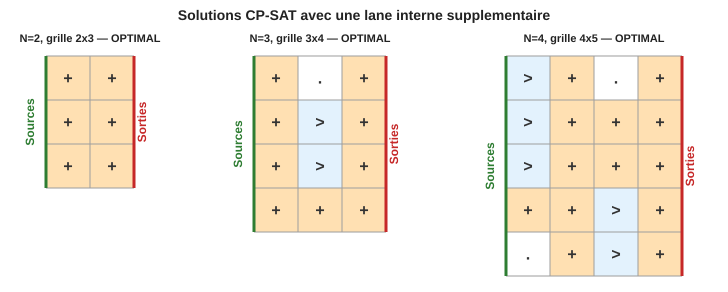

In [11]:
#nullable enable
// Figure a 3 panneaux : les solutions CP-SAT bande de la cellule precedente.
const double panelCell = 44.0, panelML = 46, panelMR = 46, panelMT = 56, panelMB = 16, gap = 28;
double panelW(int w) => panelML + w * panelCell + panelMR;
double panelH(int h) => panelMT + h * panelCell + panelMB;
int maxH = CASES.Max(c => c.Item2);
double totalW = CASES.Sum(c => panelW(c.Item1)) + gap * (CASES.Length - 1);
double totalH = panelH(maxH);
var fig = new StringBuilder();
fig.Append($"<svg xmlns='http://www.w3.org/2000/svg' width='{totalW}' height='{totalH}' viewBox='0 0 {totalW} {totalH}'>");
fig.Append($"<text x='{totalW / 2}' y='20' font-size='14' font-weight='bold' fill='#222' text-anchor='middle' font-family='Segoe UI, Arial, sans-serif'>Solutions CP-SAT avec une lane interne supplementaire</text>");
double ox = 0;
foreach (var (W, H) in CASES)
{
    var result = cpsatResults[(W, H)];
    fig.Append($"<text x='{ox + panelW(W) / 2}' y='42' font-size='11' font-weight='bold' fill='#222' text-anchor='middle' font-family='Segoe UI, Arial, sans-serif'>N={W}, grille {W}x{H} — {result.Status}</text>");
    if (result.Grid is not null)
        fig.Append(GridSvgBody(result.Grid, ox + panelML, panelMT, withSideBars: true));
    ox += panelW(W) + gap;
}
fig.Append("</svg>");
new BalancerSvg(fig.ToString())

### Lecture du résultat

La cellule ne produit qu'une figure SVG, trois panneaux portant les statuts `OPTIMAL` des cas N=2, N=3 et N=4 : c'est le rendu visuel des solutions bande déjà calculées, aucun nouveau statut n'est calculé ici.

***

## 6. Comparaison MIP vs CP-SAT (~5 min)

### Discrimination attendue

Les deux moteurs resolvent le meme modele avec une capacite totale `P` par face. Le MIP represente `P/N` en continu ; CP-SAT utilise des unites entieres.

Quand `N` ne divise pas `P`, le mode `band` conserve exactement l'injection de chaque source en repartissant ses unites entre `floor(P/N)` et `ceil(P/N)`. Le mode `ceil` exige au moins `ceil(P/N)` sur chacune des `N` sorties : la somme demandee depasse alors l'injection exacte `P`. Cette impossibilite vient de la conservation globale de chaque source, pas d'une face de sortie particuliere.

### Pourquoi une ligne supplementaire ?

La capacite partagee rend les grilles carrees `N x N` infaisables sur les cas mesures : elles ne disposent pas d'une lane interne suffisante pour redistribuer simultanement toutes les commodites. Les experiences principales emploient donc `W=N, H=N+1`, avec toujours exactement `N` sources et `N` sorties.

### Avertissement d'honnetete

Un statut `FEASIBLE` n'est pas `OPTIMAL`, et un statut `UNKNOWN` n'est pas `INFEASIBLE`. La comparaison principale s'arrete aux cas pour lesquels les deux moteurs rendent une grille. Le cas `N=5` est affiche separement comme limite de temps experimentale.

In [12]:
#nullable enable
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
Console.WriteLine("Comparaison directe sur la meme capacite physique (P = 8)");
Console.WriteLine(new string('=', 104));
Console.WriteLine($"{"N / grille",-13} {"MIP",-9} {"err MIP",-10} {"CP bande",-10} "
                  + $"{"err CP",-9} {"CP ceil",-11} {"obj MIP/CP",-12}");
Console.WriteLine(new string('-', 104));

foreach (var (W, H) in CASES)
{
    int n = W;
    var mip = mipResultsSummary[(W, H)];
    var cp = cpsatResults[(W, H)];
    var ceil = cpsatCeilResults[(W, H)];
    string mipError = mip.ShareError is double me ? $"{me:0.00e+00}" : "N/A";
    string cpError = cp.ShareError is double pe ? $"{pe:0.0000}" : "N/A";
    string objectives = (mip.Objective is double mo && cp.Objective is double po)
        ? $"{mo:0}/{po:0}" : "N/A";
    Console.WriteLine($"{n} / {W}x{H + " ",-7} {mip.Status,-9} {mipError,-10} "
                      + $"{cp.Status,-10} {cpError,-9} {ceil.Status,-11} {objectives,-12}");
}

Console.WriteLine(new string('=', 104));
Console.WriteLine("Lecture : N x N est infaisable avec une capacite partagee ; la grille");
Console.WriteLine("N x (N+1) ajoute une lane interne sans ajouter de source ni de sortie.");
Console.WriteLine("Pour N=3, le MIP livre P/N exactement ; CP-SAT repartit les 8 unites");
Console.WriteLine("en {2, 3, 3}. Le mode ceil exige 9 unites au total par source alors");
Console.WriteLine("que son injection vaut exactement 8 : l'infaisabilite vient de la");
Console.WriteLine("conservation de l'injection, pas d'une face de sortie particuliere.");

Comparaison directe sur la meme capacite physique (P = 8)


N / grille    MIP       err MIP    CP bande   err CP    CP ceil     obj MIP/CP  


--------------------------------------------------------------------------------------------------------


2 / 2x3       OPTIMAL   0.00e+00   OPTIMAL    0.0000    OPTIMAL     6/6         


3 / 3x4       OPTIMAL   4.44e-16   OPTIMAL    0.6667    INFEASIBLE  11/11       


4 / 4x5       FEASIBLE  0.00e+00   OPTIMAL    0.0000    OPTIMAL     18/18       


... (2 outputs left out)

Pour N=3, le MIP livre P/N exactement ; CP-SAT repartit les 8 unites


en {2, 3, 3}. Le mode ceil exige 9 unites au total par source alors


que son injection vaut exactement 8 : l'infaisabilite vient de la


conservation de l'injection, pas d'une face de sortie particuliere.


### Lecture du résultat

La sortie committée affiche le tableau croisé : `OPTIMAL` / `OPTIMAL` / `OPTIMAL` pour 2x3 (objectifs 6/6), `OPTIMAL` / `OPTIMAL` / `INFEASIBLE` pour 3x4 (11/11, erreur CP 0.6667) et `FEASIBLE` / `OPTIMAL` / `OPTIMAL` pour 4x5 (18/18) : le mode ceil échoue exactement lorsque N ne divise pas P.

***

## 7. Deux verifications independantes (~6 min)

### 1. Audit du routage effectivement produit

`AuditSolverFlow` ne resout rien. Il relit le tenseur retourne par le moteur et verifie : conservation par cellule et source, compatibilite des roles, egalite des faces partagees, injections, matrice de sortie et charge totale de chaque face. Il certifie donc le routage concret affiche par le solveur.

### 2. LP topologique reconstruit depuis la grille

`ValidateBalancerTopology` ignore le tenseur du solveur. Il reconstruit un nouveau programme lineaire multicommodite depuis les seuls composants de la grille, impose une capacite totale `P` par face et demande le partage continu ideal `P/N` pour toutes les sources simultanement.

Ces verdicts repondent a deux questions differentes :

- le solveur a-t-il effectivement produit un routage conforme a son domaine ?
- la topologie choisie peut-elle supporter le partage continu ideal avec les capacites physiques partagees ?

Pour CP-SAT en mode bande, une matrice entiere peut differer de `P/N` tout en etant conforme ; le LP topologique montre separement si la meme grille supporterait le partage continu ideal. Aucun max-flow source-par-source ni arc interne de capacite infinie n'est utilise.

In [13]:
#nullable enable
using LS = Google.OrTools.LinearSolver;
using LSVar = Google.OrTools.LinearSolver.Variable;
using LSExpr = Google.OrTools.LinearSolver.LinearExpr;
record FlowAudit(bool Valid, double MaxViolation, double? MaxFaceLoad, int Reached, double[,]? Matrix);
record TopologyCheck(bool Valid, string Status, double? MaxFaceLoad, double[,]? Matrix);

// Audite le tenseur de flux retourne par un solveur, sans le resoudre.
FlowAudit AuditSolverFlow(BalancerResult result, double tol = 1e-7)
{
    var grid = result.Grid;
    var tensor = result.FlowTensor;
    if (grid is null || tensor is null)
        return new FlowAudit(false, 0.0, null, 0, null);

    int H = grid.GetLength(0), W = grid.GetLength(1), N = Math.Min(H, W), P = result.P;
    var violations = new List<double>();
    void Record(double v) => violations.Add(Math.Max(0.0, v));

    // Faces actives et capacite physique totale partagee.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
        {
            int k = grid[i, j];
            var used = k == 0 ? new HashSet<int>() : new HashSet<int>(COMP_IN[k].Concat(COMP_OUT[k]));
            for (int d = 0; d < 4; d++)
            {
                double load = 0.0;
                for (int s = 0; s < N; s++) load += tensor[i, j, d, s];
                Record(load - P);
                if (!used.Contains(d)) Record(load);
            }
            if (k != 0)
                for (int s = 0; s < N; s++)
                {
                    double inc = 0.0, outg = 0.0;
                    foreach (int d in COMP_IN[k]) inc += tensor[i, j, d, s];
                    foreach (int d in COMP_OUT[k]) outg += tensor[i, j, d, s];
                    Record(Math.Abs(inc - outg));
                }
        }

    // Egalite des deux representations de chaque face interne et roles opposes.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W - 1; j++)
        {
            double maxDiff = 0.0, tot = 0.0;
            for (int s = 0; s < N; s++)
            {
                maxDiff = Math.Max(maxDiff, Math.Abs(tensor[i, j, 2, s] - tensor[i, j + 1, 3, s]));
                tot += tensor[i, j, 2, s];
            }
            Record(maxDiff);
            if (tot > tol)
            {
                int left = grid[i, j], right = grid[i, j + 1];
                var outL = left == 0 ? System.Array.Empty<int>() : COMP_OUT[left];
                var inL  = left == 0 ? System.Array.Empty<int>() : COMP_IN[left];
                var outR = right == 0 ? System.Array.Empty<int>() : COMP_OUT[right];
                var inR  = right == 0 ? System.Array.Empty<int>() : COMP_IN[right];
                bool compatible = (outL.Contains(2) && inR.Contains(3)) ||
                                  (inL.Contains(2) && outR.Contains(3));
                Record(compatible ? 0.0 : tot);
            }
        }
    for (int i = 0; i < H - 1; i++)
        for (int j = 0; j < W; j++)
        {
            double maxDiff = 0.0, tot = 0.0;
            for (int s = 0; s < N; s++)
            {
                maxDiff = Math.Max(maxDiff, Math.Abs(tensor[i, j, 1, s] - tensor[i + 1, j, 0, s]));
                tot += tensor[i, j, 1, s];
            }
            Record(maxDiff);
            if (tot > tol)
            {
                int top = grid[i, j], bottom = grid[i + 1, j];
                var outT = top == 0 ? System.Array.Empty<int>() : COMP_OUT[top];
                var inT  = top == 0 ? System.Array.Empty<int>() : COMP_IN[top];
                var outB = bottom == 0 ? System.Array.Empty<int>() : COMP_OUT[bottom];
                var inB  = bottom == 0 ? System.Array.Empty<int>() : COMP_IN[bottom];
                bool compatible = (outT.Contains(1) && inB.Contains(0)) ||
                                  (inT.Contains(1) && outB.Contains(0));
                Record(compatible ? 0.0 : tot);
            }
        }

    // Bords : injections exactes, N sorties, autres faces fermees.
    for (int j = 0; j < W; j++)
        for (int s = 0; s < N; s++)
        {
            Record(Math.Abs(tensor[0, j, 0, s]));
            Record(Math.Abs(tensor[H - 1, j, 1, s]));
        }
    for (int i = 0; i < H; i++)
        for (int s = 0; s < N; s++)
        {
            double expected = (i < N && i == s) ? P : 0.0;
            Record(Math.Abs(tensor[i, 0, 3, s] - expected));
            if (i >= N) Record(Math.Abs(tensor[i, W - 1, 2, s]));
        }

    // Matrice de sortie et bornes du domaine.
    var matrix = new double[N, N];
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
            matrix[s, o] = tensor[o, W - 1, 2, s];
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
            Record(Math.Abs(matrix[s, o] - result.ShareMatrix![s, o]));
    for (int s = 0; s < N; s++)
    {
        double rowSum = 0.0;
        for (int o = 0; o < N; o++) rowSum += matrix[s, o];
        Record(Math.Abs(rowSum - P));
    }
    if (result.Engine == "MIP" || result.Mode == "ceil")
    {
        for (int s = 0; s < N; s++)
            for (int o = 0; o < N; o++)
                Record(Math.Abs(matrix[s, o] - result.Share));
    }
    else
    {
        for (int s = 0; s < N; s++)
            for (int o = 0; o < N; o++)
            {
                Record(Math.Max(result.ShareLo - matrix[s, o], 0.0));
                Record(Math.Max(matrix[s, o] - result.ShareHi, 0.0));
            }
    }

    double maxViolation = violations.Count > 0 ? violations.Max() : 0.0;
    double maxFaceLoad = double.MinValue;
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
            {
                double t = 0.0;
                for (int s = 0; s < N; s++) t += tensor[i, j, d, s];
                maxFaceLoad = Math.Max(maxFaceLoad, t);
            }
    int reached = 0;
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
            if (matrix[s, o] > tol) reached++;
    return new FlowAudit(maxViolation <= tol, maxViolation, maxFaceLoad, reached, matrix);
}

// Cherche un partage continu ideal par LP, depuis la grille seule.
TopologyCheck ValidateBalancerTopology(int[,] grid, int nSources, int P = 8, double tol = 1e-7)
{

    int H = grid.GetLength(0), W = grid.GetLength(1), N = nSources;
    if (N != Math.Min(H, W))
        throw new ArgumentException("N doit valoir min(H, W)");
    var solver = LS.Solver.CreateSolver("GLOP")
        ?? throw new InvalidOperationException("GLOP non disponible dans OR-Tools");
    LSExpr SumL(List<LSVar> vs)
    {
        LSExpr e = vs[0];
        for (int t = 1; t < vs.Count; t++) e = e + vs[t];
        return e;
    }
    var flow = new LSVar[H, W, 4, N];
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
                for (int s = 0; s < N; s++)
                    flow[i, j, d, s] = solver.MakeNumVar(0.0, P, $"v_{i}_{j}_{d}_{s}");

    // Semantique locale fixe et capacite partagee, toutes sources confondues.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
        {
            int k = grid[i, j];
            var used = k == 0 ? new HashSet<int>() : new HashSet<int>(COMP_IN[k].Concat(COMP_OUT[k]));
            for (int d = 0; d < 4; d++)
            {
                if (!used.Contains(d))
                    for (int s = 0; s < N; s++)
                        solver.Add(flow[i, j, d, s] == 0.0);
                var tot = new List<LSVar>();
                for (int s = 0; s < N; s++) tot.Add(flow[i, j, d, s]);
                solver.Add(SumL(tot) <= P);
            }
            if (k != 0)
                for (int s = 0; s < N; s++)
                {
                    var inc = new List<LSVar>();
                    foreach (int d in COMP_IN[k]) inc.Add(flow[i, j, d, s]);
                    var outg = new List<LSVar>();
                    foreach (int d in COMP_OUT[k]) outg.Add(flow[i, j, d, s]);
                    solver.Add(SumL(inc) == SumL(outg));
                }
        }

    // Faces internes : meme valeur seulement si les roles sont complementaires.
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W - 1; j++)
        {
            int left = grid[i, j], right = grid[i, j + 1];
            var outL = left == 0 ? System.Array.Empty<int>() : COMP_OUT[left];
            var inL  = left == 0 ? System.Array.Empty<int>() : COMP_IN[left];
            var outR = right == 0 ? System.Array.Empty<int>() : COMP_OUT[right];
            var inR  = right == 0 ? System.Array.Empty<int>() : COMP_IN[right];
            bool compatible = (outL.Contains(2) && inR.Contains(3)) ||
                              (inL.Contains(2) && outR.Contains(3));
            for (int s = 0; s < N; s++)
            {
                solver.Add(flow[i, j, 2, s] == flow[i, j + 1, 3, s]);
                if (!compatible) solver.Add(flow[i, j, 2, s] == 0.0);
            }
        }
    for (int i = 0; i < H - 1; i++)
        for (int j = 0; j < W; j++)
        {
            int top = grid[i, j], bottom = grid[i + 1, j];
            var outT = top == 0 ? System.Array.Empty<int>() : COMP_OUT[top];
            var inT  = top == 0 ? System.Array.Empty<int>() : COMP_IN[top];
            var outB = bottom == 0 ? System.Array.Empty<int>() : COMP_OUT[bottom];
            var inB  = bottom == 0 ? System.Array.Empty<int>() : COMP_IN[bottom];
            bool compatible = (outT.Contains(1) && inB.Contains(0)) ||
                              (inT.Contains(1) && outB.Contains(0));
            for (int s = 0; s < N; s++)
            {
                solver.Add(flow[i, j, 1, s] == flow[i + 1, j, 0, s]);
                if (!compatible) solver.Add(flow[i, j, 1, s] == 0.0);
            }
        }

    // Bords et demande ideale exacte P/N.
    double share = (double)P / N;
    for (int j = 0; j < W; j++)
        for (int s = 0; s < N; s++)
        {
            solver.Add(flow[0, j, 0, s] == 0.0);
            solver.Add(flow[H - 1, j, 1, s] == 0.0);
        }
    for (int i = 0; i < H; i++)
        for (int s = 0; s < N; s++)
        {
            solver.Add(flow[i, 0, 3, s] == (i == s ? (double)P : 0.0));
            if (i < N) solver.Add(flow[i, W - 1, 2, s] == share);
            else solver.Add(flow[i, W - 1, 2, s] == 0.0);
        }

    var status = solver.Solve();
    string statusName = status.ToString();
    if (status != LS.Solver.ResultStatus.OPTIMAL)
        return new TopologyCheck(false, statusName, null, null);
    double maxLoad = double.MinValue;
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
            for (int d = 0; d < 4; d++)
            {
                double t = 0.0;
                for (int s = 0; s < N; s++) t += flow[i, j, d, s].SolutionValue();
                maxLoad = Math.Max(maxLoad, t);
            }
    var matrix = new double[N, N];
    double maxError = 0.0;
    for (int s = 0; s < N; s++)
        for (int o = 0; o < N; o++)
        {
            matrix[s, o] = flow[o, W - 1, 2, s].SolutionValue();
            maxError = Math.Max(maxError, Math.Abs(matrix[s, o] - share));
        }
    return new TopologyCheck(maxError <= tol && maxLoad <= P + tol, statusName, maxLoad, matrix);
}

Console.WriteLine("Deux validateurs compiles : audit du flux produit + LP topologique independant.");

Deux validateurs compiles : audit du flux produit + LP topologique independant.


### Lecture du résultat

La sortie committée affiche `Deux validateurs compiles : audit du flux produit + LP topologique independant.` : les deux vérifications sont prêtes — l'audit relit le tenseur de flux produit, le LP est reconstruit depuis la seule grille.

### Controles negatifs et validation des solutions obtenues

In [14]:
#nullable enable
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
Console.WriteLine(new string('=', 82));
Console.WriteLine("Controles negatifs et validation independante");
Console.WriteLine(new string('=', 82));

// Controle negatif 1 : lignes independantes, aucun brassage.
var gridAllBelts = new int[3, 2]; // tout belt-E
for (int i = 0; i < 3; i++) for (int j = 0; j < 2; j++) gridAllBelts[i, j] = 3;
var vBelts = ValidateBalancerTopology(gridAllBelts, 2, P: P_FULL);
Console.WriteLine($"Tout belt-E 2x3 : topologie valide={vBelts.Valid}");

// Controle negatif 2 : ancien 2x2 accepte par les max-flows separes. Il route
// chaque source seule, mais surcharge une face quand elles sont simultanees.
var gridOldHand = new int[2, 2] { { 7, 5 }, { 7, 5 } };
var vOldHand = ValidateBalancerTopology(gridOldHand, 2, P: P_FULL);
Console.WriteLine($"Ancienne grille 2x2 : topologie partagee valide={vOldHand.Valid}");

var validatorResults = new Dictionary<(string, int, int), (FlowAudit audit, TopologyCheck topology)>();
foreach (var (engine, results) in new[] { ("MIP", mipResultsSummary), ("CP-SAT", cpsatResults) })
{
    Console.WriteLine($"\n--- {engine} ---");
    foreach (var ((W, H), result) in results.OrderBy(kv => kv.Key.Item1))
    {
        var audit = AuditSolverFlow(result);
        var topology = ValidateBalancerTopology(result.Grid!, W, P: P_FULL);
        validatorResults[(engine, W, H)] = (audit, topology);
        Console.WriteLine($"N={W}, {W}x{H} : flux={audit.Valid}, LP={topology.Valid}, "
                          + $"charge max={audit.MaxFaceLoad:0.000}/{P_FULL}, atteints={audit.Reached}/{W * W}");
    }
}

var controlP9Audit = AuditSolverFlow(controlP9);
var controlP9Topology = ValidateBalancerTopology(controlP9.Grid!, 3, P: 9);
Console.WriteLine("\n--- Controle N=3, P=9 ---");
Console.WriteLine($"Flux={controlP9Audit.Valid}, LP={controlP9Topology.Valid}, "
                  + $"charge max={controlP9Audit.MaxFaceLoad:0.000}/9");

Console.WriteLine("\n--- Baseline au mixer isole ---");
var baselineVal = ValidateBalancerTopology(baselineMixer, 3, P: P_FULL);
Console.WriteLine($"Topologie valide={baselineVal.Valid} (aucun brassage vertical compatible)");
Console.WriteLine(new string('=', 82));

Controles negatifs et validation independante


Tout belt-E 2x3 : topologie valide=False


Ancienne grille 2x2 : topologie partagee valide=False



--- MIP ---


N=2, 2x3 : flux=True, LP=True, charge max=8.000/8, atteints=4/4


N=3, 3x4 : flux=True, LP=True, charge max=8.000/8, atteints=9/9


... (5 outputs left out)


--- Controle N=3, P=9 ---


Flux=True, LP=True, charge max=9.000/9



--- Baseline au mixer isole ---


Topologie valide=False (aucun brassage vertical compatible)


### Lecture du résultat

La sortie committée rapporte `flux=True, LP=True` avec `charge max=8.000/8` pour les six solutions principales (MIP et CP-SAT, atteintes 4/4, 9/9, 16/16), `False` pour les deux contrôles négatifs et pour le mixer isolé, et `Flux=True, LP=True, charge max=9.000/9` pour le contrôle P=9 : chaque grille produite passe les deux vérifications indépendantes.

### Durcissement : split equitable du mixer (contrainte C9)

La relaxation documentee en section 2 -- la repartition entre les deux sorties d'un mixer est un degre de liberte -- fait du modele une **borne superieure de faisabilite** : une topologie valide ici peut n'etre realisable par aucun splitter Factorio, qui partage son debit total en parts egales.

La contrainte C9 (`splitEquitable: true` dans `SolveCpSatBalancer`) ferme ce degre de liberte en imposant `sortie1 == sortie2` sur chaque mixer pose. Deux mesures independantes suivent :

1. **Survie des solutions principales** : on relit le tenseur de flux deja produit par les 6 solutions principales (3 MIP + 3 CP-SAT bande) et on mesure l'ecart `|sortie1 - sortie2|` de chaque mixer. Une solution survit si tous ses mixers sont deja equilibres.
2. **Existence sous durcissement** : on re-resout les memes cas avec C9 active. Si le statut reste `OPTIMAL`/`FEASIBLE`, le cas reste faisable en cherchant une nouvelle topologie equitable ; un statut `INFEASIBLE` prouverait que la relaxation elargissait reellement l'espace de recherche.

Avec des flux entiers, C9 impose en sus un total PAIR par mixer -- une contrainte physique reelle des splitters discrets (les items ne se partagent pas), pas un artefact de modelisation.

In [15]:
#nullable enable
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record SplitImb(Dictionary<(int, int), double> PerMixer, double? Worst);

// Ecart |sortie1 - sortie2| de chaque mixer, relu depuis le tenseur produit.
SplitImb MixerSplitImbalance(BalancerResult result)
{
    var grid = result.Grid; var tensor = result.FlowTensor;
    if (grid is null || tensor is null)
        return new SplitImb(new Dictionary<(int, int), double>(), null);
    int H = grid.GetLength(0), W = grid.GetLength(1);
    var perMixer = new Dictionary<(int, int), double>();
    for (int i = 0; i < H; i++)
        for (int j = 0; j < W; j++)
        {
            int k = grid[i, j];
            if (k >= 5 && k <= 8)
            {
                var outs = COMP_OUT[k].OrderBy(d => d).ToArray();
                int d1 = outs[0], d2 = outs[1];
                double t1 = 0.0, t2 = 0.0;
                int N = tensor.GetLength(3);
                for (int s = 0; s < N; s++) { t1 += tensor[i, j, d1, s]; t2 += tensor[i, j, d2, s]; }
                perMixer[(i, j)] = Math.Abs(t1 - t2);
            }
        }
    return new SplitImb(perMixer, perMixer.Count > 0 ? perMixer.Values.Max() : null);
}

Console.WriteLine("Durcissement C9 - survie des 6 solutions principales (split equitable)");
Console.WriteLine(new string('=', 84));
Console.WriteLine($"{"Engine",-8} {"N / grille",-12} {"Mixers",-8} {"Pire |s1-s2|",-14} {"Survit"}");
Console.WriteLine(new string('-', 84));

var splitMeasurements = new Dictionary<(string, int, int), (SplitImb meas, bool survives)>();
foreach (var (engine, results) in new[] { ("MIP", mipResultsSummary), ("CP-SAT", cpsatResults) })
    foreach (var ((W, H), result) in results.OrderBy(kv => kv.Key.Item1))
    {
        var meas = MixerSplitImbalance(result);
        double tol = engine == "MIP" ? 1e-6 : 0.5;
        bool survives = meas.Worst is double w && w <= tol;
        splitMeasurements[(engine, W, H)] = (meas, survives);
        string worst = meas.Worst is double ww ? $"{ww:0.0000}" : "N/A";
        Console.WriteLine($"{engine,-8} {W} / {W + "x" + H,-9} {meas.PerMixer.Count,-8} {worst,-14} {survives}");
    }
int nSurvivors = splitMeasurements.Values.Count(v => v.survives);
Console.WriteLine(new string('=', 84));
Console.WriteLine($"Lecture : {nSurvivors}/6 solutions principales survivent TELLES QUELLES");
Console.WriteLine("au durcissement C9 (tous leurs mixers deja a parts egales).");

Console.WriteLine("\nRe-resolution CP-SAT avec C9 actif (memes cas, meme bande, P = 8)");
Console.WriteLine(new string('=', 84));
var cpsatEqResults = new Dictionary<(int, int), BalancerResult>();
foreach (var (W, H) in CASES)
{
    var relaxed = cpsatResults[(W, H)];
    var hardened = SolveCpSatBalancer(W, H, timeLimit: 15.0, P: P_FULL,
                                       mode: "band", splitEquitable: true);
    cpsatEqResults[(W, H)] = hardened;
    string objs = hardened.Objective is double ho
        ? $"{relaxed.Objective:0} -> {ho:0}"
        : $"{relaxed.Objective:0} -> (aucun)";
    Console.WriteLine($"N={W}, {W}x{H} : {relaxed.Status} -> {hardened.Status}, objectif {objs}");
    if (hardened.Grid is not null)
    {
        var audit = AuditSolverFlow(hardened);
        var topology = ValidateBalancerTopology(hardened.Grid, W, P: P_FULL);
        var meas = MixerSplitImbalance(hardened);
        Console.WriteLine($"  audit flux={audit.Valid}, LP topologique={topology.Valid}, "
                          + $"pire |s1-s2|={meas.Worst:0.0000}");
    }
}
Console.WriteLine(new string('=', 84));

Console.WriteLine("\nControle divisible durci : N=3, grille 3x4, P=9, ceil + C9");
var controlP9Eq = SolveCpSatBalancer(3, 4, timeLimit: 15.0, P: 9, mode: "ceil", splitEquitable: true);
string errP9Eq = controlP9Eq.ShareError is double e9 ? $"{e9:0.0000}" : "N/A";
Console.WriteLine($"  Statut={controlP9Eq.Status}, part={controlP9Eq.Share:0.0}, erreur={errP9Eq}");

Durcissement C9 - survie des 6 solutions principales (split equitable)


Engine   N / grille   Mixers   Pire |s1-s2|   Survit


------------------------------------------------------------------------------------


MIP      2 / 2x3       6        8.0000         False


MIP      3 / 3x4       10       8.0000         False


MIP      4 / 4x5       16       8.0000         False


... (7 outputs left out)

N=3, 3x4 : OPTIMAL -> INFEASIBLE, objectif 11 -> (aucun)


N=4, 4x5 : OPTIMAL -> INFEASIBLE, objectif 18 -> (aucun)



Controle divisible durci : N=3, grille 3x4, P=9, ceil + C9


  Statut=INFEASIBLE, part=3.0, erreur=N/A


### Lecture du résultat

La sortie committée rapporte `0/6` solutions survivantes au durcissement C9 (pire `|s1-s2|` = 8.0000 sur chaque mixer), puis `OPTIMAL -> INFEASIBLE` pour les trois grilles N x (N+1) ré-résolues avec split équitable, y compris le contrôle divisible P=9 : sous C9, la lane interne ne transporte plus rien.

***
## 8. Verdict : capacite partagee et domaine numerique (~4 min)

### Question posee

Que montrent conjointement les statuts des solveurs, l'audit du flux concret et la faisabilite du partage continu ideal sur chaque grille obtenue ? Le tableau suivant est genere directement depuis ces mesures independantes.

### Resultat empirique observe

1. **La capacite est physique et partagee.** Chaque face transporte au total au plus `P`, et non `P` pour chacune des `N` sources.
2. **La ligne interne est necessaire sur les cas testes.** Les grilles `N x N` sont prouvees infaisables pour `N=2`, `N=3` et `N=4`; les grilles `N x (N+1)` fournissent une lane de redistribution sans ajouter d'entree ni de sortie.
3. **Le discriminant entier reste visible.** Pour `N=3, P=8`, CP-SAT bande conserve les huit unites avec des parts 2 ou 3, tandis que le MIP continu realise `8/3`. Le mode ceil est infaisable car `3 * ceil(8/3) > 8` pour chaque injection.
4. **Le controle divisible est reellement valide.** Le cas `N=3, P=9` passe l'audit du flux produit et le LP topologique.
5. **Les statuts restent honnetes.** Une solution `FEASIBLE` est exploitable mais son objectif n'est pas certifie optimal ; `UNKNOWN` n'autorise aucune conclusion de faisabilite.
6. **La relaxation du mixer est une borne superieure, et elle est ici necessaire.** Mesure C9 (section 7) : dans les 6 solutions principales, chaque mixer est un pass-through pur (pire `|sortie1 - sortie2| = P = 8` -- la repartition libre sert a tout devier vers une seule sortie), donc 0/6 survivent au durcissement. Re-resolues avec split equitable, les trois grilles `N x (N+1)` deviennent `INFEASIBLE` -- statut prouve, pas `UNKNOWN` -- y compris le cas divisible `N=2` ou chaque livraison vaut exactement `P/N = 4`. La cause est structurelle : tout composant admettant une entree N a aussi la sortie S parmi ses sorties (belt-S, mixer-SE, mixer-SW), or la face S est fermee sur la rangee du bas -- un mixer equitable qui y recoit du flux du nord devrait emettre autant au sud (zero force). La lane interne ne peut donc rien transporter sous C9, et la grille retombe sur le cas carre infaisable. Les solutions du modele relaxe ne sont pas "presque" realisables : la relaxation est la seule raison de leur existence, ce qui en fait un objet d'etude a part entiere.

In [16]:
#nullable enable
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
Console.WriteLine("Tableau recapitulatif du verdict (P = 8)");
Console.WriteLine(new string('=', 116));
Console.WriteLine($"{"N / grille",-13} {"MIP",-9} {"CP bande",-10} {"CP ceil",-11} "
                  + $"{"flux MIP",-10} {"LP MIP",-8} {"flux CP",-9} {"LP CP",-7} {"charge max",-11}");
Console.WriteLine(new string('-', 116));

foreach (var (W, H) in CASES)
{
    var mip = mipResultsSummary[(W, H)];
    var cp = cpsatResults[(W, H)];
    var ceil = cpsatCeilResults[(W, H)];
    var (vmAudit, vmTopology) = validatorResults[("MIP", W, H)];
    var (vcAudit, vcTopology) = validatorResults[("CP-SAT", W, H)];
    double maxLoad = Math.Max(vmAudit.MaxFaceLoad ?? 0, vcAudit.MaxFaceLoad ?? 0);
    Console.WriteLine($"{W} / {W + "x" + H,-9} {mip.Status,-9} {cp.Status,-10} "
                      + $"{ceil.Status,-11} {vmAudit.Valid + "",-10} {vmTopology.Valid + "",-8} "
                      + $"{vcAudit.Valid + "",-9} {vcTopology.Valid + "",-7} {maxLoad:0.000}/{P_FULL}");
}

Console.WriteLine(new string('=', 116));
Console.WriteLine($"Controle N=3, P=9 : statut={controlP9.Status}, "
                  + $"flux={controlP9Audit.Valid}, LP={controlP9Topology.Valid}");
Console.WriteLine($"Limite N=5, grille 5x6 : CP-SAT bande={limitN5.Status} "
                  + "(pas de comparaison MIP revendiquee)");

Tableau recapitulatif du verdict (P = 8)


N / grille    MIP       CP bande   CP ceil     flux MIP   LP MIP   flux CP   LP CP   charge max 


--------------------------------------------------------------------------------------------------------------------


2 / 2x3       OPTIMAL   OPTIMAL    OPTIMAL     True       True     True      True    8.000/8


3 / 3x4       OPTIMAL   OPTIMAL    INFEASIBLE  True       True     True      True    8.000/8


4 / 4x5       FEASIBLE  OPTIMAL    OPTIMAL     True       True     True      True    8.000/8


Controle N=3, P=9 : statut=OPTIMAL, flux=True, LP=True


Limite N=5, grille 5x6 : CP-SAT bande=FEASIBLE (pas de comparaison MIP revendiquee)


### Lecture du résultat

La sortie committée récapitule le verdict : `OPTIMAL` des deux côtés pour 2x3 et 3x4 (CP ceil `INFEASIBLE` pour 3x4), `FEASIBLE` côté MIP mais `OPTIMAL` côté CP-SAT pour 4x5, toutes les validations à `True` avec `charge max 8.000/8`, le contrôle P=9 à `OPTIMAL`, et la limite N=5 affichée `FEASIBLE` sans comparaison MIP revendiquée.

***
## 9. Sources et references (~2 min)

### Source canonique

- **Venturini, G. (2024-12-27). *Learning Solver Design: Automating Factorio Balancers***. Article de blog personnel.
  - Archive : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Constraint Programming\2024 - Venturini - Learning Solver Design - Automating Factorio Balancers.pdf`
  - Pas de licence declaree : reimplementation originale ci-dessus.
  - Attribution : grille de cellules, conservation locale et objectif de balance.
  - Divergence : mixer redistributif a une cellule au lieu du splitter a deux cellules.

- **Google OR-Tools** : package NuGet `Google.OrTools` 9.15.6755 — `Google.OrTools.Sat` (CP-SAT) et `Google.OrTools.LinearSolver` (SCIP et GLOP), appeles en natif .NET.

### Limites du notebook

- Les experiences principales couvrent `N=2`, `N=3` et `N=4` sur des grilles `W=N, H=N+1`.
- Le cas `N=5` illustre seulement une limite de temps : aucun verdict MIP comparatif n'est revendique.
- Le mixer relaxe la semantique du splitter Factorio : la repartition entre ses sorties est libre, ce qui fait du modele une borne superieure de faisabilite. Le durcissement C9 (section 7) mesure l'ecart : 0/6 solutions principales survivent au split equitable, et les trois cas principaux deviennent `INFEASIBLE` -- la relaxation n'est donc pas un angle mort, elle est quantifiee.
- Les underground belts restent hors perimetre.
- CP-SAT est deterministe ici (`num_workers=1`, graine fixe) ; SCIP n'offre pas la meme reproductibilite bit-a-bit.

### Exercice 1 : ajouter un underground belt dans le modele

Reprenez `SolveCpSatBalancer` et ajoutez un type de composant `underground belt` qui permet de transporter le flux sur 2 cellules alignees (sans obstacle entre les deux).

**Indice** : il faut une nouvelle dimension dans `comp` (la distance), et une variable binaire pour indiquer que la cellule contient l'entree ou la sortie du tunnel.

In [17]:
#nullable enable
// Exercice 1 : etendre avec underground belts (skeleton)
BalancerResult? SolveCpSatBalancerWithUnderground(int width, int height, double timeLimit = 30.0)
{
    // Version etendue avec underground belts.
    // TODO etudiant : implementer la version avec underground belts
    // Indice : ajouter 4 types d'underground (N, S, E, W) avec distance 2
    // Chaque underground couple 2 cellules alignees
    return null; // TODO etudiant
}

Console.WriteLine("Exercice 1 : skeleton defini.");

Exercice 1 : skeleton defini.


### Exercice 2 : etude de la divisibilite P mod N

Faites varier `P` dans `SolveCpSatBalancer(3, 4, P: p, mode: "ceil")` pour `p` dans `[6, 8, 9, 10, 12]`.

**Question** : le mode ceil est-il faisable exactement lorsque `3` divise `P` ? Reliez votre observation a la conservation de l'injection totale de chaque source.

In [18]:
#nullable enable
// Exercice 2 : etude de la divisibilite P mod N sur une grille 3x4
// TODO etudiant : appeler SolveCpSatBalancer(3, 4, P: p, mode: "ceil")
// pour p dans [6, 8, 9, 10, 12] et relever statut et ShareError
// Indice : comparer p % 3 avec la somme demandee 3 * ceil(p / 3)
Dictionary<int, (string, double?)>? result = null; // TODO etudiant : {p: (statut, share_error)}
Console.WriteLine("Exercice a completer : divisibilite P mod N en mode ceil.");

Exercice a completer : divisibilite P mod N en mode ceil.


### Exercice 3 : trouver la hauteur minimale

Pour `N` fixe, testez les grilles `W=N, H=N`, puis `H=N+1`, puis des hauteurs plus grandes si necessaire. Une largeur est eliminee comme minimale seulement si toutes les hauteurs precedentes ont un statut `INFEASIBLE`; `UNKNOWN` ne suffit pas.

**Question** : la premiere hauteur faisable est-elle toujours `N+1` pour `N` dans `[2, 3, 4, 5]` ? Comparez aussi la charge maximale retournee par `AuditSolverFlow`.

In [19]:
#nullable enable
// Exercice 3 : hauteur minimale avec capacite partagee
int[]? FindMinimumHeight(int nSources, int P = 8, int maxExtraRows = 3)
{
    // Cherche la premiere hauteur prouvee faisable sans sauter un UNKNOWN.
    // TODO etudiant : tester H de nSources a nSources + maxExtraRows
    // Indice : retourner null si un statut UNKNOWN empeche de prouver la minimalite
    return null; // TODO etudiant
}

Console.WriteLine("Exercice 3 : skeleton defini pour la recherche de hauteur minimale.");

Exercice 3 : skeleton defini pour la recherche de hauteur minimale.


***

## Recapitulatif

### À retenir

1. **Capacite partagee** : une face physique transporte au total au plus `P`, toutes sources confondues.
2. **Debit atteint** : chaque source injecte exactement `P` et livre `P/N` a chaque sortie en MIP continu ; CP-SAT bande conserve `P` avec des parts entieres voisines de `P/N`.
3. **Deux preuves distinctes** : l'audit controle le tenseur concret du solveur ; le LP multicommodite reconstruit certifie la capacite topologique de la grille pour le partage continu ideal.
4. **Topologie non triviale** : les cas carres testes sont infaisables avec la capacite physique ; une ligne interne supplementaire permet le routage sans ajouter de source ni de sortie.
5. **Verdicts honnetes** : `FEASIBLE` ne certifie pas l'objectif optimal et `UNKNOWN` ne prouve aucune impossibilite.
6. **Discrimination numerique** : lorsque `N` ne divise pas `P`, le MIP represente la part exacte, tandis que CP-SAT doit distribuer des entiers. Le controle divisible montre que cet ecart vient du domaine, pas d'une inferiorite du solveur.
7. **Perimetre** : formulation originale inspiree de Venturini, mixer redistributif conservatif, sans underground belts.

### Vérifiez votre compréhension

1. **Le MIP continu livre `P/N` exactement, mais CP-SAT doit partager 8 unités entre 3 sorties et termine avec une erreur maximale de 0,6667. Quand la part redevient-elle exacte, et que prouve le contrôle `P = 9` ?**
2. **Les grilles N x N (N = 2, 3, 4) sont toutes `INFEASIBLE`, alors que les grilles N x (N+1) sont résolues. Que change exactement la rangée de routage interne ?**
3. **En 3x4, le mode `ceil` est `INFEASIBLE` alors que le mode `band` est `OPTIMAL`. L'infaisabilité vient-elle d'une face de sortie, ou d'ailleurs ?**
4. **Le MIP en 4x5 rend `FEASIBLE` et non `OPTIMAL`, et le CP-SAT en 5x6 rend `FEASIBLE` avec une erreur de 0,6000. Que certifie un statut `FEASIBLE`, et que ne certifie-t-il pas ?**

<details>
<summary>Réponses</summary>

1. L'écart vient du **domaine**, pas du solveur. En 8 unités pour 3 sorties, la répartition exacte 8/3 n'est pas représentable en entiers : CP-SAT travaille donc dans la bande `[2, 3]`, et l'erreur maximale de 0,6667 est la conséquence arithmétique de ce choix — elle vaut les deux tiers d'une unité, précisément parce que 8/3 n'est pas entier. Le contrôle de divisibilité le confirme sans changer de modèle : avec `P = 9` et `N = 3`, la part redevient **3.0 exacte**, erreur **0.0000**. Même solveur, même topologie, un seul paramètre de changé : c'est le domaine qui décide de l'exactitude.
2. **La lane de routage interne** : une rangée de plus dans la grille, mais **ni source ni sortie supplémentaire** — elle donne seulement aux flux un chemin vers l'autre sens. Sans elle, la conservation des flux impose qu'une face transporte plus que `P` dès que deux sources y passent simultanément — c'est ce que prouve le contrôle négatif : l'ancienne grille 2x2, acceptée par des max-flows séparés, est refusée par la topologie partagée (`valide=False`), de même que la grille entièrement composée de belts et la baseline au mixer isolé. Cette rangée interne rend le routage possible **sans rien ajouter au problème**.
3. De la **conservation de l'injection**, pas d'une face de sortie. Le mode `ceil` exige que chaque source livre `ceil(P/N)` unités à chaque sortie, soit 9 unités au total pour une injection de 8 : le modèle est alors arithmétiquement infaisable, quelle que soit la topologie. C'est la différence entre une bande `[floor, ceil]` — qui autorise des parts melangees — et un plancher strict. Le carnet le formule ainsi : l'infaisabilité vient de la conservation de l'injection, pas d'une face de sortie particulière.
4. `FEASIBLE` certifie qu'une solution **respectant les contraintes** a été trouvée, et rien de plus : ni l'optimalité de l'objectif, ni l'absence d'une meilleure solution. Le MIP en 4x5 a atteint sa limite de temps sans prouver l'optimalité ; le CP-SAT en 5x6 a trouvé une répartition dont l'erreur sur la part atteint 0,6000. Symétriquement, `UNKNOWN` ne prouverait **aucune** impossibilité : c'est l'absence de verdict, pas un verdict d'absence. C'est pourquoi le carnet revendique les deux moteurs séparément — le MIP en 4x5 est `FEASIBLE` là où le CP-SAT est `OPTIMAL`, sans qu'on puisse en déduire une supériorité de l'un sur l'autre.

</details>

### Pour aller plus loin

- **Version Python** : [Frontieres-02-Factorio-Balancer-Python](Frontieres-02-Factorio-Balancer-Python.ipynb) — le même comparatif MIP vs CP-SAT en Python (numpy, Matplotlib, OR-Tools Python)
- **Carnet suivant (C#)** : [Frontieres-05-CoveringArrays-Guarantee-Audit](Frontieres-05-CoveringArrays-Guarantee-Audit-CSharp.ipynb) — les tableaux de couverture : garantir que chaque interaction possible a été rencontrée, et auditer une suite incomplète
- **Partie** : [Index de la Partie 5 — Frontières](README.md) — les onze carnets de la famille et leurs audits de garantie
- **Lectures** : Venturini (2024), *Learning Solver Design: Automating Factorio Balancers* (source canonique, archivée dans la bibliographie partagée) et la documentation **Google OR-Tools** (`linear_solver` pour SCIP et GLOP, `cp_model` pour CP-SAT) — déjà citées en fin de carnet